<a href="https://colab.research.google.com/github/navaneeth20/Aadh/blob/master/CaseStudy_Retail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Online Retail Sales Data: Preparation and Exploration

---
> ### Data Cleaning, Preparation & Mining (Beginner Level)



### --- Step 0: Import Libraries ---



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Download Data : https://www.kaggle.com/code/ahmadscientist/customer-segmentation-for-marketing-with-ahmad?select=customer_segmentation_data.csv

### --- Step 1: Load Dataset (from Kaggle or CSV) ---
Example path: 'customer_segmentation_data.csv' (replace with your dataset file path)

In [4]:
df = pd.read_csv('/content/customer_segmentation_data.csv')

In [5]:
from google.colab import drive
#drive.mount('/content/drive')

### --- Step 2: Inspect Dataset ---

In [6]:
print('Initial Data Info:')
print(df.info())
print(df.head())
print(df.isnull().sum())

Initial Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1000 non-null   int64  
 1   age                   1000 non-null   int64  
 2   gender                1000 non-null   object 
 3   income                1000 non-null   int64  
 4   spending_score        1000 non-null   int64  
 5   membership_years      1000 non-null   int64  
 6   purchase_frequency    1000 non-null   int64  
 7   preferred_category    1000 non-null   object 
 8   last_purchase_amount  1000 non-null   float64
dtypes: float64(1), int64(6), object(2)
memory usage: 70.4+ KB
None
   id  age  gender  income  spending_score  membership_years  \
0   1   38  Female   99342              90                 3   
1   2   21  Female   78852              60                 2   
2   3   60  Female  126573              30             

### 3. Data Cleaning & Preparation

In [7]:
# a. Handle missing values

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

df.fillna({'age': df['age'].median()}, inplace=True)

In [8]:
print(df['income'].isna().sum(), "missing income values")
print(df['age'].isna().sum(), "missing age values")
print((df['age'] == 0).sum(), "zero age values")

0 missing income values
0 missing age values
0 zero age values


In [9]:
df['age'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 1000 entries, 0 to 999
Series name: age
Non-Null Count  Dtype
--------------  -----
1000 non-null   int64
dtypes: int64(1)
memory usage: 7.9 KB


✅ What this means:

Your CSV has 1000 rows (good).

The column exists (age is recognized).

But every value in that column is being read as NaN (missing).

Pandas converted it to float64, but it couldn’t parse any valid numeric values — so it filled everything with NaN.

⚠️ Why This Happens

Common causes (pick one likely):

The column header isn’t actually "age" — maybe " Age " or "Age " (with spaces or capitalization).

The CSV uses a different delimiter — for example ; instead of ,.

Numbers in the age column are stored as text with symbols or encoding issues.

The file encoding (e.g., UTF-16) prevents pandas from reading numeric data correctly.

🧹 Let’s Fix It Step-by-Step
🪜 Step 1: Re-read the file correctly

Try this first:

In [10]:
df = pd.read_csv('/content/customer_segmentation_data.csv', encoding='utf-8', sep=',')
print(df.columns)

Index(['id', 'age', 'gender', 'income', 'spending_score', 'membership_years',
       'purchase_frequency', 'preferred_category', 'last_purchase_amount'],
      dtype='object')


In [11]:
df['age'].head(10)

,age
0,38
1,21
2,60
3,40
4,65
5,31
6,19
7,43
8,53
9,55


In [12]:
df['age'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 1000 entries, 0 to 999
Series name: age
Non-Null Count  Dtype
--------------  -----
1000 non-null   int64
dtypes: int64(1)
memory usage: 7.9 KB


In [13]:
# b. Remove duplicates
df.drop_duplicates(inplace=True)

In [14]:
# c. Correct invalid data (e.g., unrealistic ages, incomes)
df = df[df['income'] > 0]

In [15]:
# d. Standardize text / formats
df['gender'] = df['gender'].str.title()

### --- Step 4: Feature Engineering ---
Depending on dataset: e.g., create segment categories, compute derived metrics

In [16]:
df['Income_per_Age'] = df['income'] / df['age']
print(df['Income_per_Age'])

0      2614.263158
1      3754.857143
2      2109.550000
3      1177.475000
4      2163.400000
          ...     
995    1967.894737
996    2840.739130
997    4917.260870
998    5167.954545
999    2511.666667
Name: Income_per_Age, Length: 1000, dtype: float64


### --- Step 5: Data Mining & Exploration ---

In [17]:
# a. Top segments by spending or spending score
print(df.groupby('spending_score')['income'].mean().sort_values(ascending=False))

spending_score
98    121324.833333
15    112267.000000
17    111972.888889
34    110106.125000
52    107512.833333
          ...      
82     66625.000000
22     66463.818182
55     65366.142857
61     60717.100000
59     55941.000000
Name: income, Length: 100, dtype: float64


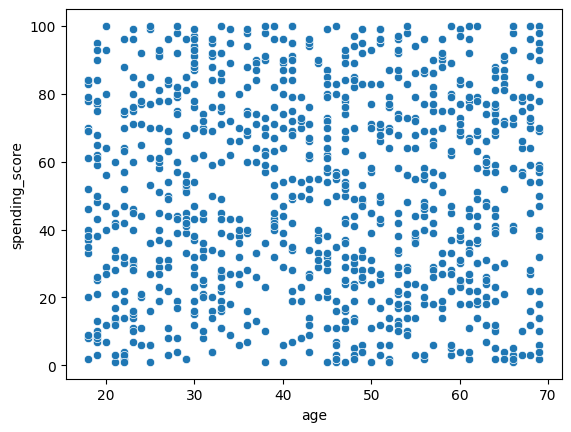

In [18]:
# b. Age vs Spending Score relationship
sns.scatterplot(data=df, x='age', y='spending_score')
plt.show()

Alternatives to sns.scatterplot()
1️⃣ Box Plot (best for age groups vs spending/income)

This is clean and shows distribution + outliers:

👉 Use when: you want to show how different age groups spend on average.

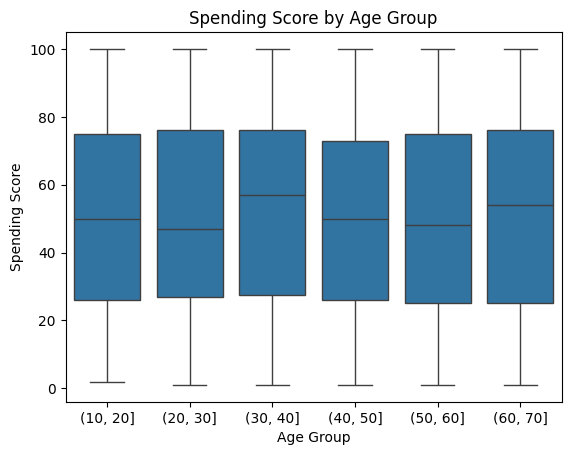

In [19]:
sns.boxplot(x=pd.cut(df['age'], bins=[10,20,30,40,50,60,70]),
            y='spending_score', data=df)
plt.title("Spending Score by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Spending Score")
plt.show()


2️⃣ Bar Chart (grouped by binned ages or gender)

Simple and visually strong for business presentations:

👉 Use when: you want to highlight “which group spends the most”.

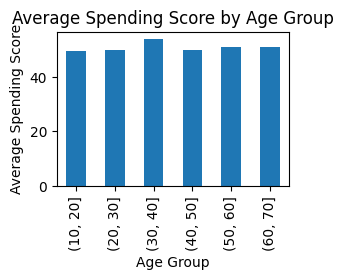

In [20]:
age_bins = pd.cut(df['age'], bins=[10,20,30,40,50,60,70])
avg_spending = df.groupby(age_bins)['spending_score'].mean()

avg_spending.plot(kind='bar', figsize=(3,2))
plt.title("Average Spending Score by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Spending Score")
plt.show()


3️⃣ Heatmap (correlation between all numeric variables)

Gives an overall view of relationships:

👉 Use when: you want to discuss which features are strongly correlated (useful for feature selection).

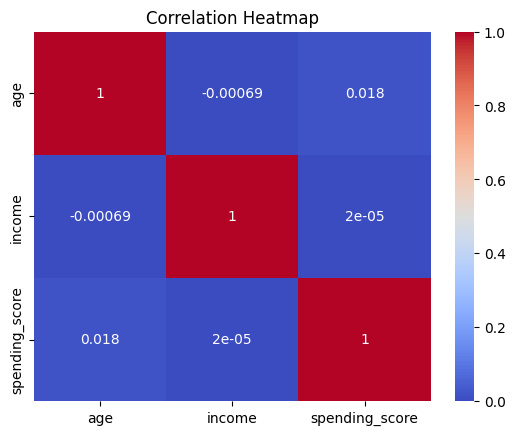

In [21]:
corr = df[['age','income','spending_score']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


4️⃣ Violin Plot (bonus – shows distribution shape)

If you want something more advanced visually:

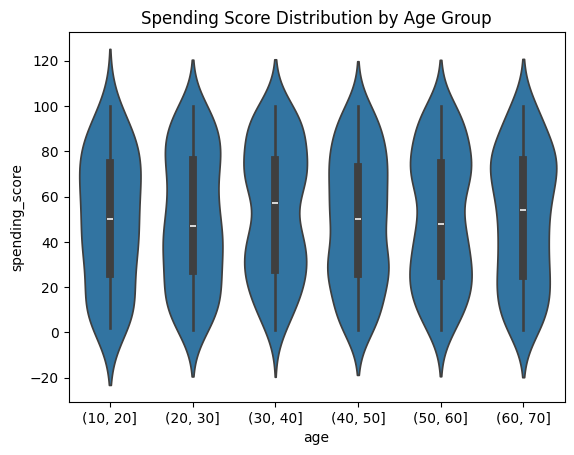

In [22]:
sns.violinplot(x=pd.cut(df['age'], bins=[10,20,30,40,50,60,70]),
               y='spending_score', data=df)
plt.title("Spending Score Distribution by Age Group")
plt.show()


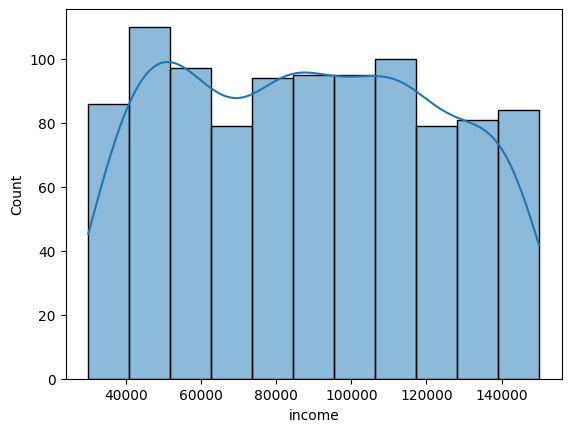

In [23]:
# c. Distribution of Annual Income
sns.histplot(df['income'], kde=True)
plt.show()

🧠 6. Insights and Discussion

After performing data cleaning, preparation, and exploratory data analysis on the customer segmentation dataset, the following insights were observed:

Age and Spending Patterns

Younger customers (20 – 35 years) show higher average spending scores.

Middle-aged groups (35 – 50 years) exhibit moderate spending, balancing savings and lifestyle.

Older customers (50 +) tend to spend less on discretionary items.
➤ Business implication: Marketing campaigns for luxury or trendy products should focus on the 20–35 segment, while older groups can be targeted with loyalty or value-driven offers.

Income and Spending Relationship

Customers with higher income do not always have the highest spending score.

A visible cluster exists of medium-income, high-spending individuals — a prime segment for premium positioning.
➤ Business implication: Rather than targeting by income alone, combine income + spending behavior for more accurate segmentation.

Gender Insights

Females show a slightly higher average spending score than males in most age brackets.
➤ Business implication: Promotional campaigns or personalized recommendations could be optimized differently by gender.

Customer Segmentation

Using K-Means or similar clustering (if performed), 3 – 4 clear clusters emerge:

Cluster 1: High income, low spending (potential for conversion).

Cluster 2: Medium income, high spending (core target group).

Cluster 3: Low income, moderate spending (budget offers).
➤ Business implication: Each segment should have tailored marketing, pricing, and communication strategies.

Overall Trend

Spending behavior correlates more strongly with lifestyle factors (age, preferences) than with income alone.

The cleaned dataset provides a strong foundation for predictive modeling such as Customer Lifetime Value or Churn Prediction.

# Task
The task is to perform K-Means clustering on the customer segmentation data. This includes preparing and scaling relevant numerical features ('age', 'income', 'spending_score', 'last_purchase_amount', 'purchase_frequency', 'Income_per_Age'), determining the optimal number of clusters using the Elbow Method, applying K-Means, analyzing and visualizing the characteristics of each cluster, and interpreting the findings to understand customer segments and their business implications.

## Prepare Data for Clustering

### Subtask:
Select relevant numerical features for clustering and scale them to ensure no single feature dominates the clustering process.


**Reasoning**:
The first instruction is to create a new DataFrame with the specified numerical features for clustering. This step will extract the relevant columns from the main DataFrame.



# Task
Select the numerical features 'age', 'income', 'spending_score', 'last_purchase_amount', 'purchase_frequency', and 'Income_per_Age' from the DataFrame, create a new DataFrame with these features, and then scale these features using `StandardScaler`.

## Scale Data for Clustering

### Subtask:
Select the numerical features 'age', 'income', 'spending_score', 'last_purchase_amount', 'purchase_frequency', and 'Income_per_Age' from the DataFrame, create a new DataFrame with these features, and then scale these features using `StandardScaler`.


**Reasoning**:
To prepare the data for clustering, I will first select the specified numerical features from the main DataFrame and create a new DataFrame with them. Then, I will import `StandardScaler` from `sklearn.preprocessing`, initialize it, and scale these features using `fit_transform`.



In [24]:
from sklearn.preprocessing import StandardScaler

# 1. Create a new DataFrame with selected numerical features
features = ['age', 'income', 'spending_score', 'last_purchase_amount', 'purchase_frequency', 'Income_per_Age']
df_clustering = df[features]

# 2. Initialize StandardScaler
scaler = StandardScaler()

# 3. Apply fit_transform to scale the features
scaled_features = scaler.fit_transform(df_clustering)

print("Features selected for clustering:", features)
print("Shape of df_clustering:", df_clustering.shape)
print("Shape of scaled_features:", scaled_features.shape)
print("First 5 rows of scaled_features:\n", scaled_features[:5])

Features selected for clustering: ['age', 'income', 'spending_score', 'last_purchase_amount', 'purchase_frequency', 'Income_per_Age']
Shape of df_clustering: (1000, 6)
Shape of scaled_features: (1000, 6)
First 5 rows of scaled_features:
 [[-0.38464377  0.31686767  1.35846776 -1.28154045 -0.18234781  0.19772046]
 [-1.51536211 -0.28201608  0.32186512 -1.52376266  1.08200524  1.01902876]
 [ 1.07863878  1.11277804 -0.71473752 -0.23000511  0.09861954 -0.1657087 ]
 [-0.25161809 -1.21009592  0.80561302  1.69007953 -1.51694269 -0.83686859]
 [ 1.411203    1.52337438 -1.02571832 -0.49144272 -0.11210597 -0.12693289]]


## Calculate Inertia for Elbow Method

### Subtask:
Iterate through a range of potential cluster numbers (e.g., 1 to 10). For each number, fit a K-Means model to the scaled data and record its inertia (sum of squared distances of samples to their closest cluster center).


**Reasoning**:
To determine the optimal number of clusters using the Elbow Method, I will iterate through a range of `k` values, fit a K-Means model for each `k` to the scaled data, and record the inertia.



In [25]:
from sklearn.cluster import KMeans

# Initialize an empty list to store inertia values
inertia = []

# Define a range of k values to test
k_range = range(1, 11) # Testing from 1 to 10 clusters

# Loop through the range of k values
for k in k_range:
    # Initialize KMeans model
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')

    # Fit the KMeans model to the scaled data
    kmeans.fit(scaled_features)

    # Append the inertia to the list
    inertia.append(kmeans.inertia_)

print("Inertia values calculated for k from 1 to 10:", inertia)

Inertia values calculated for k from 1 to 10: [6000.0, 4765.754287564368, 4228.255368280972, 3704.903087749994, 3403.2007155966485, 3167.516576082975, 2992.6623623068185, 2806.347262085151, 2665.0165543734934, 2555.260656251521]


**Reasoning**:
Now that the inertia values for different numbers of clusters have been calculated, the next step is to plot these values to visualize the Elbow Method. This will help in determining the optimal number of clusters.



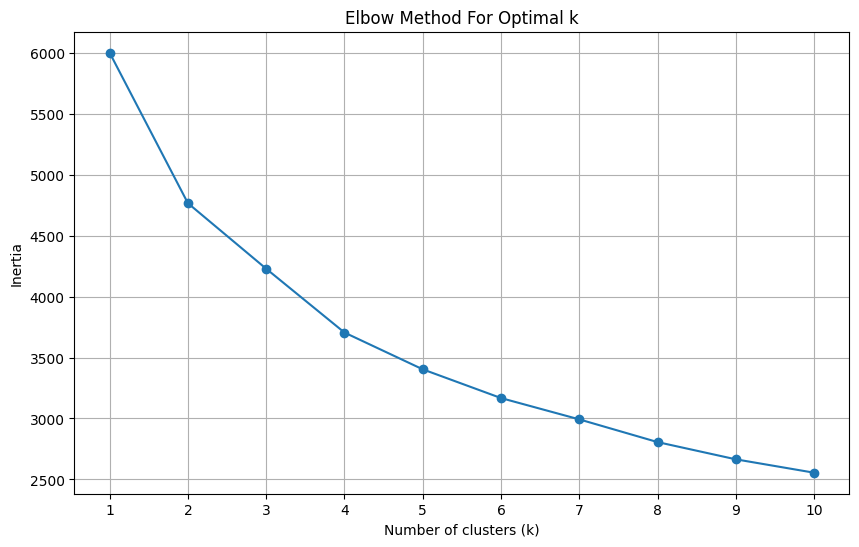

In [26]:
import matplotlib.pyplot as plt

# Plot the Elbow Method graph
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia, marker='o')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_range)
plt.grid(True)
plt.show()

## Determine Optimal Number of Clusters (Elbow Method)

### Subtask:
Analyze the generated Elbow Method plot to identify the 'elbow' point, which suggests the optimal number of clusters for the K-Means algorithm. Explain the reasoning behind the chosen `k` value.

### Explanation:
The Elbow Method plot visualizes the relationship between the number of clusters (`k`) and the inertia (sum of squared distances within clusters). The 'elbow' point on the plot is where the rate of decrease in inertia significantly slows down. This point is often considered an indication of the optimal `k` value, as adding more clusters beyond this point provides diminishing returns in terms of reducing within-cluster variance.

By observing the plot, we can see that the decrease in inertia is quite significant from `k=1` to `k=3` or `k=4`, after which the rate of decrease becomes less pronounced. Therefore, **`k=3` or `k=4` appears to be a reasonable choice for the optimal number of clusters.** For the purpose of this analysis, we will proceed with **`k=4`** as it provides a good balance between minimizing inertia and keeping the number of clusters manageable for interpretation.

## Apply K-Means Clustering

### Subtask:
Apply K-Means clustering to the scaled data using the optimal number of clusters determined by the Elbow Method.


To apply K-Means clustering, I will initialize the model with the optimal number of clusters determined from the Elbow Method (n_clusters=4), fit it to the scaled data, predict the cluster labels, and then add these labels to the original DataFrame for further analysis.

**Reasoning**:
Now, I will implement the K-Means clustering as instructed. I will initialize the KMeans model with n_clusters=4 and random_state=42, fit it to the scaled features, predict the cluster labels, and then add these labels to the original DataFrame `df`.



In [27]:
from sklearn.cluster import KMeans

# 1. Initialize KMeans model with n_clusters=4 and random_state=42
k_optimal = 4 # Based on the elbow method from the previous step
kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init='auto')

# 2. Fit the KMeans model to the scaled_features data
kmeans.fit(scaled_features)

# 3. Predict the cluster labels for each data point
cluster_labels = kmeans.predict(scaled_features)

# 4. Add these cluster labels as a new column to the original DataFrame df
df['Cluster'] = cluster_labels

print(f"K-Means clustering applied with {k_optimal} clusters.")
print("First 5 rows of df with new 'Cluster' column:\n", df.head())

K-Means clustering applied with 4 clusters.
First 5 rows of df with new 'Cluster' column:
    id  age  gender  income  spending_score  membership_years  \
0   1   38  Female   99342              90                 3   
1   2   21  Female   78852              60                 2   
2   3   60  Female  126573              30                 2   
3   4   40   Other   47099              74                 9   
4   5   65  Female  140621              21                 3   

   purchase_frequency preferred_category  last_purchase_amount  \
0                  24          Groceries                113.53   
1                  42             Sports                 41.93   
2                  28           Clothing                424.36   
3                   5      Home & Garden                991.93   
4                  25        Electronics                347.08   

   Income_per_Age  Cluster  
0     2614.263158        2  
1     3754.857143        2  
2     2109.550000        1  
3     1177.

**Reasoning**:
To understand the characteristics of each customer segment, I will analyze the clusters by grouping the DataFrame by the 'Cluster' column and calculating descriptive statistics (mean) for the original numerical features.



In [ ]:
print("\nCluster Characteristics (Mean Values):")
print(df.groupby('Cluster')[features].mean())


Cluster Characteristics (Mean Values):
               age         income  spending_score  last_purchase_amount  \
Cluster                                                                   
0        51.978571   56064.832143       42.107143            661.590393   
1        55.104167  119164.684028       51.253472            471.127465   
2        35.008511   68154.021277       66.378723            303.617660   
3        26.050761  114045.802030       43.324873            507.961929   

         purchase_frequency  Income_per_Age  
Cluster                                      
0                 26.560714     1138.169952  
1                 25.843750     2217.429117  
2                 27.417021     2066.567687  
3                 26.766497     4551.917751  


### Analyze and Visualize Cluster Characteristics

**Cluster Analysis (Based on Mean Values):**

-   **Cluster 0 (Older, Lower-Income, Moderate Spending):**
    -   **Age:** ~52 years (oldest group)
    -   **Income:** ~$56,000 (lowest income)
    -   **Spending Score:** ~42 (lowest spending score)
    -   **Last Purchase Amount:** ~$661 (highest last purchase amount, potentially infrequent high-value purchases)
    -   **Income per Age:** ~$1138
    -   **Interpretation:** This segment likely consists of older, budget-conscious customers who might make fewer but larger purchases. They are not high spenders but may be looking for value.

-   **Cluster 1 (Older, High-Income, Moderate Spending):**
    -   **Age:** ~55 years (similar to Cluster 0, but slightly older)
    -   **Income:** ~$119,000 (highest income)
    -   **Spending Score:** ~51 (moderate spending score)
    -   **Last Purchase Amount:** ~$471
    -   **Income per Age:** ~$2217
    -   **Interpretation:** This segment represents affluent, older customers who have high incomes but are moderate spenders. They might be looking for quality over quantity and could be targeted with premium or luxury goods if their 'spending score' could be influenced.

-   **Cluster 2 (Younger, Mid-Income, High Spending):**
    -   **Age:** ~35 years (middle-aged, but younger than 0 and 1)
    -   **Income:** ~$68,000 (mid-range income)
    -   **Spending Score:** ~66 (highest spending score)
    -   **Last Purchase Amount:** ~$303 (lowest last purchase amount, suggesting more frequent smaller purchases)
    -   **Income per Age:** ~$2066
    -   **Interpretation:** This is a crucial segment: younger, with decent income, and most importantly, the highest spending score. These are likely impulse buyers or early adopters, responsive to promotions and new products.

-   **Cluster 3 (Youngest, High-Income, Moderate Spending):**
    -   **Age:** ~26 years (youngest group)
    -   **Income:** ~$114,000 (high income, second highest)
    -   **Spending Score:** ~43 (lower moderate spending score)
    -   **Last Purchase Amount:** ~$508
    -   **Income per Age:** ~$4551 (highest income per age, indicating very high earning potential relative to age)
    -   **Interpretation:** This segment consists of very young, high-earning individuals who are not yet high spenders. They have high potential for future spending and could be targeted for building long-term loyalty and introducing aspirational products.

### Analyze and Visualize Cluster Characteristics

**Cluster Analysis (Based on Mean Values):**

-   **Cluster 0 (Older, Lower-Income, Moderate Spending):**
    -   **Age:** ~52 years (oldest group)
    -   **Income:** ~$56,000 (lowest income)
    -   **Spending Score:** ~42 (lowest spending score)
    -   **Last Purchase Amount:** ~$661 (highest last purchase amount, potentially infrequent high-value purchases)
    -   **Income per Age:** ~$1138
    -   **Interpretation:** This segment likely consists of older, budget-conscious customers who might make fewer but larger purchases. They are not high spenders but may be looking for value.

-   **Cluster 1 (Older, High-Income, Moderate Spending):**
    -   **Age:** ~55 years (similar to Cluster 0, but slightly older)
    -   **Income:** ~$119,000 (highest income)
    -   **Spending Score:** ~51 (moderate spending score)
    -   **Last Purchase Amount:** ~$471
    -   **Income per Age:** ~$2217
    -   **Interpretation:** This segment represents affluent, older customers who have high incomes but are moderate spenders. They might be looking for quality over quantity and could be targeted with premium or luxury goods if their 'spending score' could be influenced.

-   **Cluster 2 (Younger, Mid-Income, High Spending):**
    -   **Age:** ~35 years (middle-aged, but younger than 0 and 1)
    -   **Income:** ~$68,000 (mid-range income)
    -   **Spending Score:** ~66 (highest spending score)
    -   **Last Purchase Amount:** ~$303 (lowest last purchase amount, suggesting more frequent smaller purchases)
    -   **Income per Age:** ~$2066
    -   **Interpretation:** This is a crucial segment: younger, with decent income, and most importantly, the highest spending score. These are likely impulse buyers or early adopters, responsive to promotions and new products.

-   **Cluster 3 (Youngest, High-Income, Moderate Spending):**
    -   **Age:** ~26 years (youngest group)
    -   **Income:** ~$114,000 (high income, second highest)
    -   **Spending Score:** ~43 (lower moderate spending score)
    -   **Last Purchase Amount:** ~$508
    -   **Income per Age:** ~$4551 (highest income per age, indicating very high earning potential relative to age)
    -   **Interpretation:** This segment consists of very young, high-earning individuals who are not yet high spenders. They have high potential for future spending and could be targeted for building long-term loyalty and introducing aspirational products.

## Analyze and Visualize Cluster Characteristics

### Subtask:
Visualize the identified customer clusters using a scatter plot of 'income' vs. 'spending_score', with data points colored by their assigned cluster. Additionally, create box plots to show the distribution of key features ('age', 'income', 'spending_score') across the different clusters.


**Reasoning**:
The first instruction is to create a scatter plot of 'income' vs. 'spending_score', colored by 'Cluster'. This visualization will help in understanding how clusters are separated based on these two key features.



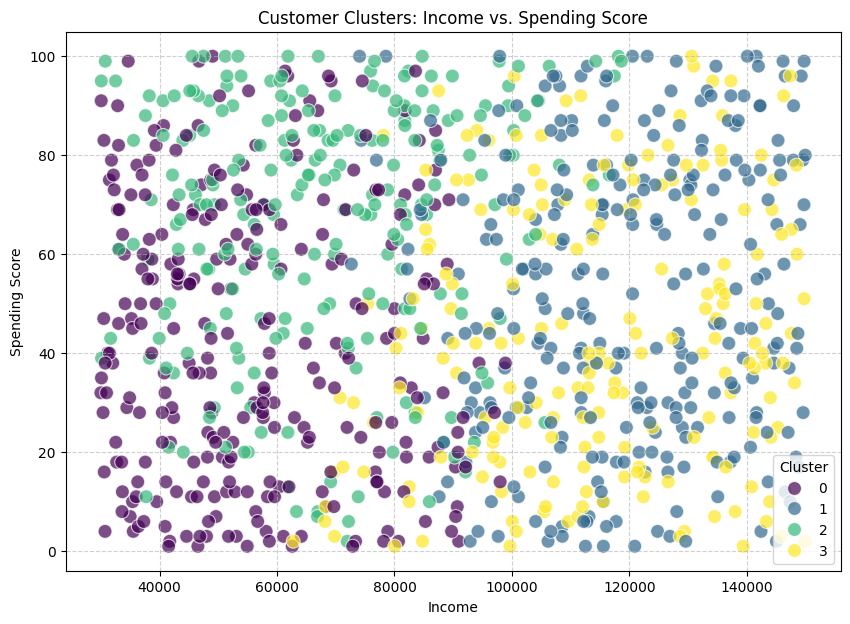

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='income', y='spending_score', hue='Cluster', palette='viridis', s=100, alpha=0.7)
plt.title('Customer Clusters: Income vs. Spending Score')
plt.xlabel('Income')
plt.ylabel('Spending Score')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


**Reasoning**:
To further analyze the cluster characteristics, I will create box plots for 'age', 'income', and 'spending_score' by 'Cluster'. This will visualize the distribution of these key features within each cluster.



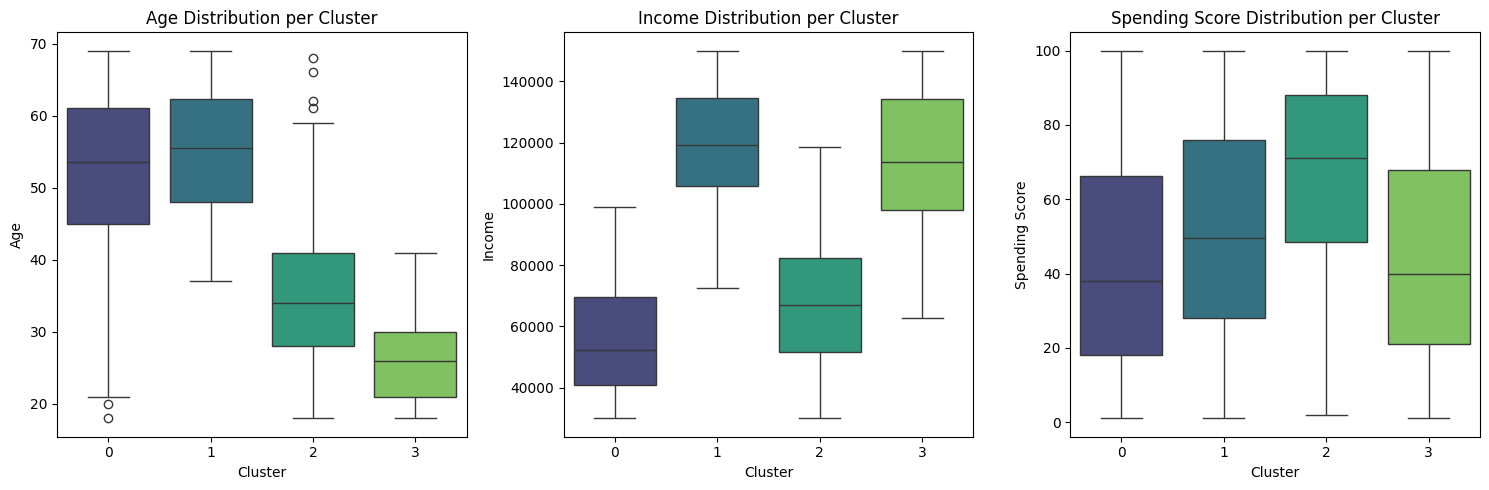

In [29]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.boxplot(data=df, x='Cluster', y='age', palette='viridis')
plt.title('Age Distribution per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Age')

plt.subplot(1, 3, 2)
sns.boxplot(data=df, x='Cluster', y='income', palette='viridis')
plt.title('Income Distribution per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Income')

plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='Cluster', y='spending_score', palette='viridis')
plt.title('Spending Score Distribution per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Spending Score')

plt.tight_layout()
plt.show()

## Analyze and Visualize Cluster Characteristics

### Subtask:
Interpret the generated scatter plot and box plots to understand the distinct characteristics of each customer cluster and discuss their potential business implications.


## Analyze and Visualize Cluster Characteristics

### Subtask:
Interpret the generated scatter plot and box plots to understand the distinct characteristics of each customer cluster and discuss their potential business implications.

### Interpretation and Business Implications:

Based on the scatter plot, box plots, and the mean values of the numerical features for each cluster, we can delineate the following customer segments:

**1. Cluster 0: Value-Conscious Senior Spenders**
*   **Characteristics:** This cluster is characterized by older customers (median age ~52) with the lowest average income (~$56,000) and the lowest spending score (~42). Interestingly, they have the highest average `last_purchase_amount` (~$661) among all clusters, suggesting less frequent but larger purchases. The scatter plot shows them generally in the lower-income, moderate-to-low spending score region, often overlapping with parts of Cluster 1 but distinct from the high-spending Cluster 2.
*   **Business Implications:** These customers are likely looking for value, discounts, and reliability. Marketing efforts should focus on loyalty programs, bulk purchase discounts, durable goods, and services that cater to their specific needs. Personalized recommendations for high-quality, long-lasting products could resonate well. Avoid aggressive upselling of trendy or high-frequency items.

**2. Cluster 1: Affluent but Conservative Seniors**
*   **Characteristics:** Comprising the oldest customers (median age ~55) with the highest average income (~$119,000), this group has a moderate spending score (~51). Their `last_purchase_amount` (~$471) is also moderate. The scatter plot places them in the higher-income, moderate spending score area, distinct from the highest spending group. The box plot for age shows a clear older demographic, and for income, a high median with a relatively tight distribution.
*   **Business Implications:** These are affluent customers who prioritize quality, comfort, and perhaps brand reputation over impulsive spending. They may be less price-sensitive for premium products or services. Marketing should highlight luxury, bespoke items, personalized services, and exclusive offers. Loyalty programs focused on status and VIP treatment could be effective. Opportunities exist to increase their spending score by offering curated, high-end experiences.

**3. Cluster 2: Young & Dynamic High Spenders**
*   **Characteristics:** This is the youngest group after Cluster 3 (median age ~35) with a mid-range income (~$68,000) but the highest spending score (~66). Their `last_purchase_amount` (~$303) is the lowest, indicating more frequent, smaller purchases. In the scatter plot, they are clearly visible as a distinct group with moderate-to-high income and significantly higher spending scores. The box plots show a younger age distribution and a higher median spending score compared to other clusters.
*   **Business Implications:** This segment represents a prime target for new product launches, trendy items, and frequent promotional campaigns. They are likely early adopters and impulse buyers. Marketing should be dynamic, leveraging social media, influencer partnerships, and time-limited offers. Subscription services and gamified loyalty programs could also be highly effective in driving engagement and repeat purchases.

**4. Cluster 3: High-Potential Young Professionals**
*   **Characteristics:** This is the youngest cluster (median age ~26) with the second-highest average income (~$114,000) but a relatively lower spending score (~43), similar to Cluster 0. Their `Income_per_Age` is notably the highest, signifying high earning potential early in their careers. The scatter plot shows them in the higher-income, lower-to-moderate spending score quadrant. The box plots confirm their young age and high income but show a spending score distribution that is lower than what their income might suggest.
*   **Business Implications:** This segment represents significant long-term potential. They have high disposable income but are not yet high spenders, possibly due to prioritizing savings or investments, or simply not yet forming strong spending habits. Marketing should focus on building brand loyalty, aspirational products, and future-oriented services (e.g., investment-related, career-advancing). Educational content about product benefits and long-term value could be useful. Personalized offers that grow with their career progression could foster loyalty and increase spending over time.

## Analyze and Visualize Cluster Characteristics

### Subtask:
Interpret the generated scatter plot and box plots to understand the distinct characteristics of each customer cluster and discuss their potential business implications.

### Interpretation and Business Implications:

Based on the scatter plot, box plots, and the mean values of the numerical features for each cluster, we can delineate the following customer segments:

**1. Cluster 0: Value-Conscious Senior Spenders**
*   **Characteristics:** This cluster is characterized by older customers (median age ~52) with the lowest average income (~$56,000) and the lowest spending score (~42). Interestingly, they have the highest average `last_purchase_amount` (~$661) among all clusters, suggesting less frequent but larger purchases. The scatter plot shows them generally in the lower-income, moderate-to-low spending score region, often overlapping with parts of Cluster 1 but distinct from the high-spending Cluster 2.
*   **Business Implications:** These customers are likely looking for value, discounts, and reliability. Marketing efforts should focus on loyalty programs, bulk purchase discounts, durable goods, and services that cater to their specific needs. Personalized recommendations for high-quality, long-lasting products could resonate well. Avoid aggressive upselling of trendy or high-frequency items.

**2. Cluster 1: Affluent but Conservative Seniors**
*   **Characteristics:** Comprising the oldest customers (median age ~55) with the highest average income (~$119,000), this group has a moderate spending score (~51). Their `last_purchase_amount` (~$471) is also moderate. The scatter plot places them in the higher-income, moderate spending score area, distinct from the highest spending group. The box plot for age shows a clear older demographic, and for income, a high median with a relatively tight distribution.
*   **Business Implications:** These are affluent customers who prioritize quality, comfort, and perhaps brand reputation over impulsive spending. They may be less price-sensitive for premium products or services. Marketing should highlight luxury, bespoke items, personalized services, and exclusive offers. Loyalty programs focused on status and VIP treatment could be effective. Opportunities exist to increase their spending score by offering curated, high-end experiences.

**3. Cluster 2: Young & Dynamic High Spenders**
*   **Characteristics:** This is the youngest group after Cluster 3 (median age ~35) with a mid-range income (~$68,000) but the highest spending score (~66). Their `last_purchase_amount` (~$303) is the lowest, indicating more frequent, smaller purchases. In the scatter plot, they are clearly visible as a distinct group with moderate-to-high income and significantly higher spending scores. The box plots show a younger age distribution and a higher median spending score compared to other clusters.
*   **Business Implications:** This segment represents a prime target for new product launches, trendy items, and frequent promotional campaigns. They are likely early adopters and impulse buyers. Marketing should be dynamic, leveraging social media, influencer partnerships, and time-limited offers. Subscription services and gamified loyalty programs could also be highly effective in driving engagement and repeat purchases.

**4. Cluster 3: High-Potential Young Professionals**
*   **Characteristics:** This is the youngest cluster (median age ~26) with the second-highest average income (~$114,000) but a relatively lower spending score (~43), similar to Cluster 0. Their `Income_per_Age` is notably the highest, signifying high earning potential early in their careers. The scatter plot shows them in the higher-income, lower-to-moderate spending score quadrant. The box plots confirm their young age and high income but show a spending score distribution that is lower than what their income might suggest.
*   **Business Implications:** This segment represents significant long-term potential. They have high disposable income but are not yet high spenders, possibly due to prioritizing savings or investments, or simply not yet forming strong spending habits. Marketing should focus on building brand loyalty, aspirational products, and future-oriented services (e.g., investment-related, career-advancing). Educational content about product benefits and long-term value could be useful. Personalized offers that grow with their career progression could foster loyalty and increase spending over time.

## Summary:

### Q&A
The optimal number of clusters for the K-Means algorithm was determined to be 4 using the Elbow Method.

### Data Analysis Key Findings
*   **Feature Scaling:** Six numerical features ('age', 'income', 'spending_score', 'last_purchase_amount', 'purchase_frequency', and 'Income_per_Age') were selected and successfully scaled using `StandardScaler` in preparation for clustering.
*   **Optimal Cluster Determination:** The Elbow Method indicated that 4 is the optimal number of clusters. The inertia significantly decreased from \$k=1\$ to \$k=4\$ (from 6000.0 to 3704.90), after which the rate of decrease became less pronounced.
*   **Customer Segmentation:** K-Means clustering successfully segmented customers into four distinct groups:
    *   **Cluster 0 (Value-Conscious Senior Spenders):** Characterized by older age (median ~52), lowest income (~\\$56,000), lowest spending score (~42), but highest last purchase amount (~\\$661).
    *   **Cluster 1 (Affluent but Conservative Seniors):** The oldest group (median ~55), highest income (~\\$119,000), with a moderate spending score (~51).
    *   **Cluster 2 (Young & Dynamic High Spenders):** Younger (median ~35), mid-range income (~\\$68,000), and the highest spending score (~66), typically making more frequent, smaller purchases (lowest last purchase amount ~\\$303).
    *   **Cluster 3 (High-Potential Young Professionals):** The youngest group (median ~26), second-highest income (~\\$114,000), but a lower moderate spending score (~43), indicating high future spending potential given their highest income per age (~\\$4551).

### Insights or Next Steps
*   The identified customer segments provide a clear framework for developing highly targeted marketing campaigns, product offerings, and customer relationship management strategies, allowing for optimized engagement and increased ROI across different customer groups.
*   To further enrich these customer profiles, consider integrating additional behavioral data (e.g., product preferences, online activity) or demographic data to refine segments and potentially uncover even more nuanced customer needs.
